In [1]:
"""
Based upon:
1995 Quantum Networks for Elementary Arithmetic Operations
"""
!pip install qiskit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 44.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.2 MB/s eta 0:00:00


In [2]:
!pip install qiskit-aer --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 39.4 MB/s eta 0:00:00


In [3]:
import numpy as np
from numpy import pi
from numpy import sqrt

from qiskit import QuantumCircuit
from qiskit_aer.primitives import Sampler
from qiskit.visualization import plot_histogram


In [4]:
# Define functions for the ripple carry adder.
def sum(circ, cin, a, b):
    circ.cx(a,b)
    circ.cx(cin,b)

def carry(circ, cin, a, b, cout):
    circ.ccx(a, b, cout)
    circ.cx(a, b)
    circ.ccx(cin, b, cout)

def carry_rev(circ, cin, a, b, cout):
    circ.ccx(cin, b, cout)
    circ.cx(a, b)
    circ.ccx(a, b, cout)


In [5]:
#quantum sum of 3 bits (1-bit FA)
qc = QuantumCircuit(4,2)

# encode inputs in qubits 0, 1 and 2
#use the X gates to toggle the input qubit values
xinput = [1,1,0]  #vary these input values for all 8 cases
if xinput[2] == 1:
  qc.x(0)
if xinput[1] == 1:
  qc.x(1)
if xinput[0] == 1:
  qc.x(2)
qc.barrier()

#QC carry ...
carry(qc, 0, 1, 2, 3)
qc.barrier()

qc.cx(1,2)
qc.barrier()

#QC sum ...
sum(qc, 0, 1, 2)
qc.barrier()

# extract outputs
qc.measure(2,0) # extract Sum value
qc.measure(3,1) # extract Cout value

qc.draw()

░                 ░       ░            ░       
q_0: ──────░─────────────■───░───────░────────■───░───────
     ┌───┐ ░             │   ░       ░        │   ░       
q_1: ┤ X ├─░───■────■────┼───░───■───░───■────┼───░───────
     ├───┤ ░   │  ┌─┴─┐  │   ░ ┌─┴─┐ ░ ┌─┴─┐┌─┴─┐ ░ ┌─┐   
q_2: ┤ X ├─░───■──┤ X ├──■───░─┤ X ├─░─┤ X ├┤ X ├─░─┤M├───
     └───┘ ░ ┌─┴─┐└───┘┌─┴─┐ ░ └───┘ ░ └───┘└───┘ ░ └╥┘┌─┐
q_3: ──────░─┤ X ├─────┤ X ├─░───────░────────────░──╫─┤M├
           ░ └───┘     └───┘ ░       ░            ░  ║ └╥┘
c: 2/════════════════════════════════════════════════╩══╩═
                                                     0  1

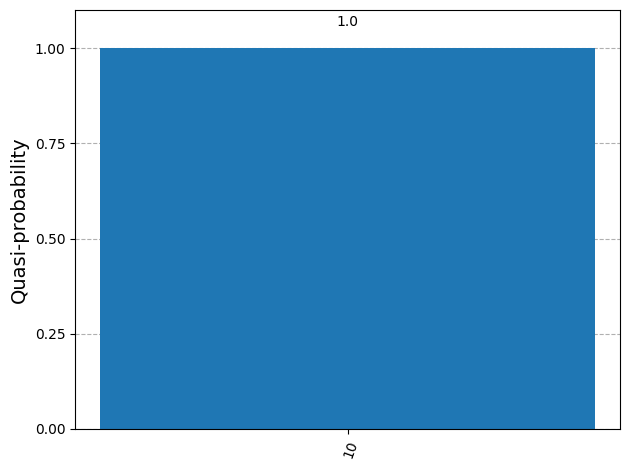

In [6]:
results = Sampler().run(qc).result()
statistics = results.quasi_dists[0].binary_probabilities()
plot_histogram(statistics)

In [7]:
#quantum sum of 3 bits (1-bit FA)
#Another way with 5-bits
#(anticipating a design for an n-bit FA)
qc = QuantumCircuit(5,2)

# encode inputs in qubits 0, 1 and 2
#use the X gates to toggle the input qubit values
xinput = [1,1,1]  #vary these input values for all 8 cases
if xinput[2] == 1:
  qc.x(0)
if xinput[1] == 1:
  qc.x(1)
if xinput[0] == 1:
  qc.x(2)
qc.barrier()

#QC carry ...
carry(qc, 0, 1, 2, 3)
qc.barrier()

qc.cx(3,4)
qc.barrier()

#QC carry reverse ...
carry_rev(qc, 0, 1, 2, 3)
qc.barrier()

#QC sum ...
sum(qc, 0, 1, 2)
qc.barrier()

# extract outputs
qc.measure(2,0) # extract Sum value
qc.measure(4,1) # extract Cout value

qc.draw()


┌───┐ ░                 ░       ░                 ░            ░       
q_0: ┤ X ├─░─────────────■───░───────░───■─────────────░────────■───░───────
     ├───┤ ░             │   ░       ░   │             ░        │   ░       
q_1: ┤ X ├─░───■────■────┼───░───────░───┼────■────■───░───■────┼───░───────
     ├───┤ ░   │  ┌─┴─┐  │   ░       ░   │  ┌─┴─┐  │   ░ ┌─┴─┐┌─┴─┐ ░ ┌─┐   
q_2: ┤ X ├─░───■──┤ X ├──■───░───────░───■──┤ X ├──■───░─┤ X ├┤ X ├─░─┤M├───
     └───┘ ░ ┌─┴─┐└───┘┌─┴─┐ ░       ░ ┌─┴─┐└───┘┌─┴─┐ ░ └───┘└───┘ ░ └╥┘   
q_3: ──────░─┤ X ├─────┤ X ├─░───■───░─┤ X ├─────┤ X ├─░────────────░──╫────
           ░ └───┘     └───┘ ░ ┌─┴─┐ ░ └───┘     └───┘ ░            ░  ║ ┌─┐
q_4: ──────░─────────────────░─┤ X ├─░─────────────────░────────────░──╫─┤M├
           ░                 ░ └───┘ ░                 ░            ░  ║ └╥┘
c: 2/══════════════════════════════════════════════════════════════════╩══╩═
                                                                       0  1

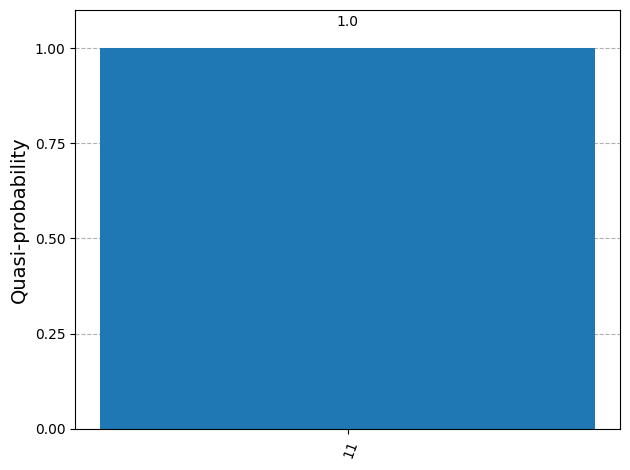

In [8]:
results = Sampler().run(qc).result()
statistics = results.quasi_dists[0].binary_probabilities()
plot_histogram(statistics)

In [9]:
#2-bit FA
qc = QuantumCircuit(7,3)

#Qubits:  0    1    2   3              4   5     6
#Input:  cin0  a0  b0  cin1(=cout0)   a1   b1   cin2(=cout1)

#Qubits:    0    1    2            3     4    5             6
#Output:   cin0  a0  a0+b0+cin0   |0>   a1   a1+b1+cin1   cin2(=cout1)

#use the X gates to toggle the input qubit values
a = [1,1]
b = [1,0]
if a[1] == 1:
  qc.x(1)
if a[0] == 1:
  qc.x(4)

if b[1] == 1:
  qc.x(2)
if b[0] == 1:
  qc.x(5)

qc.barrier()

#QC carry ...
carry(qc, 0, 1, 2, 3)
qc.barrier()

carry(qc, 3,4,5,6)
qc.barrier()

qc.cx(4,5)
qc.barrier()
sum(qc, 3,4,5)
qc.barrier()
qc.barrier()
qc.barrier()

#QC carry reverse ...
carry_rev(qc, 0, 1, 2, 3)
qc.barrier()

#QC sum ...
sum(qc, 0, 1, 2)
qc.barrier()

# extract outputs
qc.measure(2,0) # extract Sum_0
qc.measure(5,1) # extract Sum_1
qc.measure(6,2) # extract Sum_2

qc.draw()

░                 ░                 ░       ░            ░  ░  ░ »
q_0: ──────░─────────────■───░─────────────────░───────░────────────░──░──░─»
     ┌───┐ ░             │   ░                 ░       ░            ░  ░  ░ »
q_1: ┤ X ├─░───■────■────┼───░─────────────────░───────░────────────░──░──░─»
     └───┘ ░   │  ┌─┴─┐  │   ░                 ░       ░            ░  ░  ░ »
q_2: ──────░───■──┤ X ├──■───░─────────────────░───────░────────────░──░──░─»
           ░ ┌─┴─┐└───┘┌─┴─┐ ░                 ░       ░            ░  ░  ░ »
q_3: ──────░─┤ X ├─────┤ X ├─░─────────────■───░───────░────────■───░──░──░─»
     ┌───┐ ░ └───┘     └───┘ ░             │   ░       ░        │   ░  ░  ░ »
q_4: ┤ X ├─░─────────────────░───■────■────┼───░───■───░───■────┼───░──░──░─»
     ├───┤ ░                 ░   │  ┌─┴─┐  │   ░ ┌─┴─┐ ░ ┌─┴─┐┌─┴─┐ ░  ░  ░ »
q_5: ┤ X ├─░─────────────────░───■──┤ X ├──■───░─┤ X ├─░─┤ X ├┤ X ├─░──░──░─»
     └───┘ ░                 ░ ┌─┴─┐└───┘┌─┴─┐ ░ └───┘ ░ └───┘└───┘ ░  ░  ░ »
q_6: ──────░─────────────────░─┤ X ├─────┤ X ├─░───────░────────────░──░──░─»
           ░                 ░ └───┘     └───┘ ░       ░            ░  ░  ░ »
c: 3/═══════════════════════════════════════════════════════════════════════»
                                                                            »
«                     ░            ░          
«q_0: ──■─────────────░────────■───░──────────
«       │             ░        │   ░          
«q_1: ──┼────■────■───░───■────┼───░──────────
«       │  ┌─┴─┐  │   ░ ┌─┴─┐┌─┴─┐ ░ ┌─┐      
«q_2: ──■──┤ X ├──■───░─┤ X ├┤ X ├─░─┤M├──────
«     ┌─┴─┐└───┘┌─┴─┐ ░ └───┘└───┘ ░ └╥┘      
«q_3: ┤ X ├─────┤ X ├─░────────────░──╫───────
«     └───┘     └───┘ ░            ░  ║       
«q_4: ────────────────░────────────░──╫───────
«                     ░            ░  ║ ┌─┐   
«q_5: ────────────────░────────────░──╫─┤M├───
«                     ░            ░  ║ └╥┘┌─┐
«q_6: ────────────────░────────────░──╫──╫─┤M├
«                     ░            ░  ║  ║ └╥┘
«c: 3/════════════════════════════════╩══╩══╩═
«                                     0  1  2

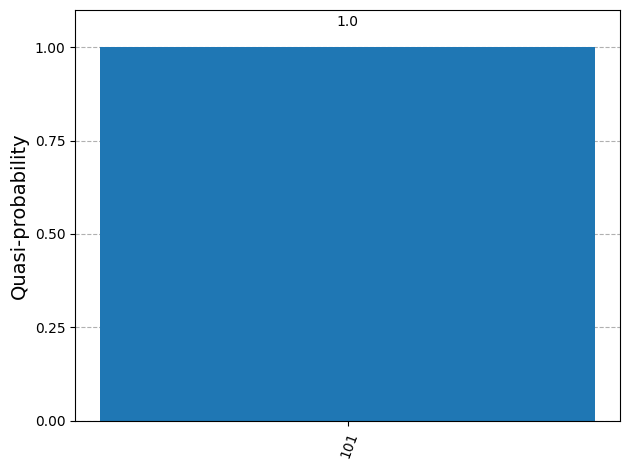

In [10]:
results = Sampler().run(qc).result()
statistics = results.quasi_dists[0].binary_probabilities()
plot_histogram(statistics)